> **中文阅读版**：本文件是 `10_crypto_perps_eda.ipynb` 的 Markdown 翻译副本。代码、输出、图表和路径保持原样；专有名词和标识符保留英文。
# 加密永续合约：探索性数据分析

**Docker image**：`ml4t`

## 目的

剖析 Binance Futures 的 19 份永续合约的小时级 OHLCV 数据集，以及捕捉永续合约与现货基差的 8 小时级溢价指数（Premium Index）。本 notebook 在第 6 章开始策略工作之前，明确数据形状、单位、覆盖范围和 OHLC 完整性。

## 学习目标

- 通过标准加载器加载小时级 OHLCV 与 8 小时级溢价指数数据。
- 记录溢价指数的单位（小数，乘以 100 得到百分比）。
- 量化 OHLCV 与溢价数据之间的跨频率连接覆盖率。
- 运行 OHLC 不变式检查，并检查时间戳缺口。

## 本书参考

§2.2，“资产类别的市场数据格局”——其中的数字资产部分。

## 前置条件

- 熟悉日频 OHLCV 股票数据（`01_us_equities_eda`）。
- `$ML4T_DATA_PATH/crypto/` 下的 Binance Futures parquet（OHLCV + premium）。
- 方法在 `11_crypto_premium_analysis` 中继续；案例研究流水线位于 `case_studies/crypto_perps_funding/` 下。

In [1]:
"""Crypto perps EDA: hourly OHLCV and premium index exploration."""

import plotly.graph_objects as go
import polars as pl

from data import load_crypto_perps, load_crypto_premium
from utils.data_quality import check_ohlc_invariants, per_asset_stats
from utils.style import COLORS, show_plotly_with_alt

### 声明的参数

`MAX_SYMBOLS` 为零时会加载所有符号。CI 会覆盖该值以缩小 notebook 的运行规模，因此必须将其传递给加载器，而不是放在一旁闲置不用。

In [2]:
MAX_SYMBOLS = 0

# Half-width, in percent, of the premium histogram's x-axis. The distribution's standard
# deviation is around a tenth of a percent, so this is several standard deviations either way
# and still a small fraction of the range the tail reaches.
PREMIUM_AXIS_PCT = 0.5

## 1. 加载并检查 OHLCV

来自 Binance Futures 的 19 种加密货币的小时级 OHLCV 数据。
交易为 24/7（每年 8,760 小时，而股票为 252 天）。

In [3]:
ohlcv = load_crypto_perps(frequency="1h", max_symbols=MAX_SYMBOLS)

print("=== OHLCV Dataset ===")
print(f"Shape: {ohlcv.shape}")
print(f"Columns: {ohlcv.columns}")

=== OHLCV Dataset ===
Shape: (866484, 7)
Columns: ['timestamp', 'open', 'high', 'low', 'close', 'volume', 'symbol']


In [4]:
# Schema overview
print("\nSchema:")
for col, dtype in ohlcv.schema.items():
    print(f"  {col}: {dtype}")


Schema:
  timestamp: Datetime(time_unit='ms', time_zone='UTC')
  open: Float64
  high: Float64
  low: Float64
  close: Float64
  volume: Float64
  symbol: String


## 2. 覆盖范围摘要

In [5]:
# Symbols and date range
symbols = ohlcv["symbol"].unique().sort().to_list()
print("=== Coverage ===")
print(f"Number of symbols: {len(symbols)}")
print(f"\nSymbols: {', '.join(symbols)}")

=== Coverage ===
Number of symbols: 19

Symbols: AAVEUSDT, ADAUSDT, APTUSDT, ATOMUSDT, AVAXUSDT, BNBUSDT, BTCUSDT, COMPUSDT, DOGEUSDT, DOTUSDT, ETHUSDT, INJUSDT, LINKUSDT, MKRUSDT, NEARUSDT, SOLUSDT, SUIUSDT, UNIUSDT, XRPUSDT


In [6]:
# Overall date range
date_range = ohlcv.select(
    [
        pl.col("timestamp").min().alias("start"),
        pl.col("timestamp").max().alias("end"),
        pl.col("timestamp").n_unique().alias("unique_hours"),
    ]
)

print(f"\nDate range: {date_range['start'][0]} to {date_range['end'][0]}")
print(f"Unique hours: {date_range['unique_hours'][0]:,}")


Date range: 2020-01-01 00:00:00+00:00 to 2025-12-31 23:00:00+00:00
Unique hours: 52,608


In [7]:
# Per-symbol statistics
symbol_stats = per_asset_stats(
    ohlcv,
    time_col="timestamp",
    asset_col="symbol",
    price_col="close",
    volume_col="volume",
)

print("\nSymbol Statistics (top 5 by volume):")
symbol_stats.sort("avg_volume", descending=True).head(5)


Symbol Statistics (top 5 by volume):


symbol,rows,start,end,avg_price,avg_volume
str,u32,"datetime[ms, UTC]","datetime[ms, UTC]",f64,f64
"""DOGEUSDT""",48015,2020-07-10 09:00:00 UTC,2025-12-31 23:00:00 UTC,0.137195,2.7592e8
"""XRPUSDT""",52360,2020-01-06 08:00:00 UTC,2025-12-31 23:00:00 UTC,0.89747,5.2917e7
"""ADAUSDT""",51880,2020-01-31 08:00:00 UTC,2025-12-31 23:00:00 UTC,0.644055,3.0205e7
"""SUIUSDT""",23360,2023-05-03 16:00:00 UTC,2025-12-31 23:00:00 UTC,1.917873,1.2587e7
"""NEARUSDT""",45568,2020-10-15 08:00:00 UTC,2025-12-31 23:00:00 UTC,4.297627,2.1940e6


### 不同日期的合约列表

投资范围并非固定不变：BTC 和少数主流币种自 2020 年起就已存在，而更新的合约（SUI 于 2023 年上市）则在之后才启用。按月统计不同符号的数量，可以明确体现分批上线的情况，而这是任何横截面信号都必须考虑的覆盖范围。

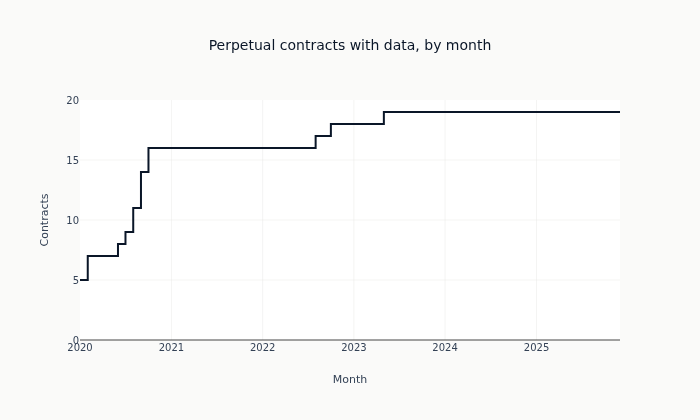

In [8]:
active_by_month = (
    ohlcv.with_columns(pl.col("timestamp").dt.truncate("1mo").alias("month"))
    .group_by("month")
    .agg(pl.col("symbol").n_unique().alias("contracts"))
    .sort("month")
)

fig = go.Figure()
fig.add_trace(
    go.Scatter(
        x=active_by_month["month"].to_list(),
        y=active_by_month["contracts"].to_list(),
        mode="lines",
        line=dict(color=COLORS["blue"], width=2, shape="hv"),
        name="Contracts with data",
    )
)
fig.update_layout(
    title="Perpetual contracts with data, by month",
    xaxis_title="Month",
    yaxis_title="Contracts",
    yaxis_range=[0, 20],
    height=420,
)
show_plotly_with_alt(
    fig,
    "A step line counting how many perpetual contracts have data in each month, from 2020 to the end of the sample. It rises in discrete jumps as new contracts list and does not fall.",
)

## 3. 溢价指数数据

溢价指数衡量永续合约相对标的指数的偏离程度。它常被描述为两个价格之间的简单相对差值，这种描述足以用来建立直觉，但从某种意义上说是错误的，且这一点在后续很重要：Binance 是用 *impact bid and ask* 相对于价格指数计算的，并且当指数位于两者之间时，会有一个项为零。精确定义及其后果见下文的数据质量部分。

- 正溢价：永续合约的可执行买价高于指数
- 负溢价：其可执行卖价低于指数

哪一方支付并不由该符号决定。资金费率（funding）是溢价经过相对于正利率的钳制（clamp）后得到的，而该钳制会把一整段溢价——包括零和轻微负值——固定到利率本身，这部分由多头支付。`11_crypto_premium_analysis` 推导了公式，并度量每种情况出现的频率。

### 单位

溢价数值以**小数**存储，而不是百分比：数值千分之一表示 0.1%。显示前乘以一百。列名中没有任何内容记录这一约定，因此下面打印出的范围才能确定它——这些量级只有在一种解读下才说得通。

In [9]:
premium = load_crypto_premium(frequency="8h", max_symbols=MAX_SYMBOLS)
print("=== Premium Dataset ===")
print(f"Shape: {premium.shape}")
print(f"Columns: {premium.columns}")

=== Premium Dataset ===
Shape: (107839, 6)
Columns: ['timestamp', 'symbol', 'premium_index_open', 'premium_index_high', 'premium_index_low', 'premium_index_close']


In [10]:

premium_range = premium.select(
    [
        pl.col("premium_index_close").min().alias("min"),
        pl.col("premium_index_close").max().alias("max"),
        pl.col("premium_index_close").mean().alias("mean"),
        pl.col("premium_index_close").std().alias("std"),
    ]
)

print("\nPremium Range (decimals):")
print(f"  Mean: {premium_range['mean'][0]:.6f} ({premium_range['mean'][0] * 100:.4f}%)")
print(f"  Std:  {premium_range['std'][0]:.6f} ({premium_range['std'][0] * 100:.4f}%)")
print(f"  Min:  {premium_range['min'][0]:.6f} ({premium_range['min'][0] * 100:.4f}%)")
print(f"  Max:  {premium_range['max'][0]:.6f} ({premium_range['max'][0] * 100:.4f}%)")


Premium Range (decimals):
  Mean: -0.000111 (-0.0111%)
  Std:  0.001137 (0.1137%)
  Min:  -0.191547 (-19.1547%)
  Max:  0.012701 (1.2701%)


### 基差很小，直到它不再小

溢价几乎始终处于百分之零点几以内，而上面打印出的范围显示了极端值能延伸到多远。该分布围绕中心主体并不对称，而案例研究中的资金费率策略正是建立在这种不对称性之上，因此值得绘图展示而非制表。

坐标轴经过裁剪，以便中心主体无论如何都清晰可辨。若不裁剪，单次错位就会决定整个范围，而策略实际交易的观测会坍缩成一根柱。裁剪半宽被声明为参数，而不是直接写进图中，并且注释承载了裁剪所隐藏的数值，因此这一选择没有掩盖任何信息。

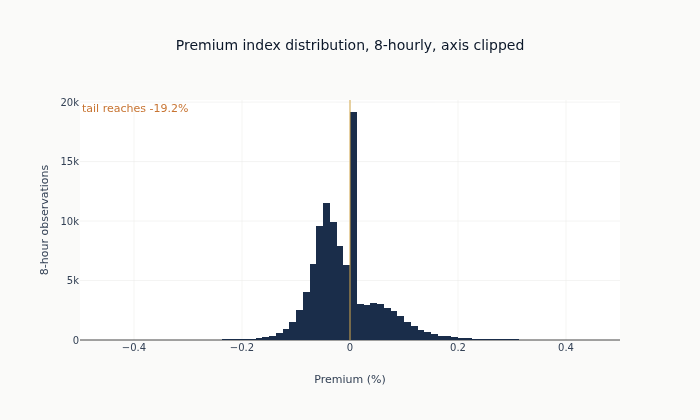

In [11]:
premium_pct = (premium["premium_index_close"] * 100).to_list()

fig = go.Figure()
fig.add_trace(
    go.Histogram(
        x=premium_pct,
        xbins=dict(start=-PREMIUM_AXIS_PCT, end=PREMIUM_AXIS_PCT, size=PREMIUM_AXIS_PCT / 40),
        marker_color=COLORS["slate"],
        name="Premium (%)",
    )
)
fig.add_vline(x=0, line_color=COLORS["amber"], line_width=1)
fig.add_annotation(
    x=-PREMIUM_AXIS_PCT,
    y=1,
    xref="x",
    yref="paper",
    text=f"tail reaches {min(premium_pct):.1f}%",
    showarrow=False,
    xanchor="left",
    yanchor="top",
    font=dict(color=COLORS["copper"]),
)
fig.update_layout(
    title="Premium index distribution, 8-hourly, axis clipped",
    xaxis_title="Premium (%)",
    yaxis_title="8-hour observations",
    xaxis_range=[-PREMIUM_AXIS_PCT, PREMIUM_AXIS_PCT],
    height=420,
)
show_plotly_with_alt(
    fig,
    f"A histogram of the eight-hourly premium index in percent, with a vertical line at zero "
    f"and the horizontal axis clipped to plus or minus {PREMIUM_AXIS_PCT} percent. The mass is "
    f"a single narrow spike centred on zero, taller than its neighbours, tapering within about "
    f"a fifth of a percent in both directions. An annotation at the top left names how far the "
    f"negative tail runs beyond the clipped range.",
)

## 4. 数据质量

这些是原始交易所 K 线，而不是经过调整的面板，因此这里的 OHLC 关系是精确的而非近似的：最高价是已记录价格的最大值，最低价是同一组价格的最小值。没有任何数值乘以调整比率，因此不存在某种算术会使最高价和收盘价在价格相同时出现一点偏差。

`check_ohlc_invariants` 会按相对容差进行比较，这正是调整后的面板所需要的，而 `03_etfs_eda` 展示了其原因。在这个文件上，该容差没有任何需要宽容之处，因此该单元格把百分比转换回 K 线数量：任何规模的任何违反都将是数据采集中的缺陷，而不是舍入误差；计数为零比一个四舍五入到一百的百分比更直白地说明了这一点。

In [12]:
# OHLC invariants
invariants = check_ohlc_invariants(ohlcv)
print(f"OHLC invariants over {len(ohlcv):,} raw hourly bars:")
for row in invariants.iter_rows(named=True):
    breaches = round((100 - row["valid_pct"]) / 100 * len(ohlcv))
    status = "[OK]" if breaches == 0 else "[FAIL]"
    print(f"  {status} {row['check']}: {row['valid_pct']:.4f}%  ({breaches} bars outside)")

OHLC invariants over 866,484 raw hourly bars:
  [OK] high_gte_low: 100.0000%  (0 bars outside)
  [OK] high_gte_open: 100.0000%  (0 bars outside)
  [OK] high_gte_close: 100.0000%  (0 bars outside)
  [OK] low_lte_open: 100.0000%  (0 bars outside)
  [OK] low_lte_close: 100.0000%  (0 bars outside)
  [OK] volume_non_negative: 100.0000%  (0 bars outside)


In [13]:
ohlcv_nulls = ohlcv.null_count().sum_horizontal()[0]
premium_nulls = premium.null_count().sum_horizontal()[0]
print(f"Null values: OHLCV={ohlcv_nulls}, Premium={premium_nulls}")

Null values: OHLCV=0, Premium=0


### 点质量，以及如何判断其成因

两个文件都不含空值。其价值完全取决于其背后的编码方式，因为缺失被记录为 null 时能被空值检查发现，而缺失被记录为看似有效的数字时则不能。因此值得寻找第二种情况。

溢价指数（premium index）有一个明显的候选。它是一个连续量，存储至八位小数，标准差约为千分之一，然而其收盘值中有很大一部分恰好为零——在那种分辨率下，连续分布本应几乎永远不会产生这样的值。

In [14]:
_close = pl.col("premium_index_close")
_zero_rows = premium.filter(_close == 0)
_nonzero = premium.filter(_close != 0)["premium_index_close"].abs()

print(
    f"Premium closes of exactly zero: {_zero_rows.height:,} of {len(premium):,} "
    f"({100 * _zero_rows.height / len(premium):.2f}%)"
)
print(f"Smallest non-zero magnitude in the file: {_nonzero.min():.10f}")
print(f"Standard deviation of the close:         {premium['premium_index_close'].std():.6f}")
print(
    f"  so the storage quantum is 1/{premium['premium_index_close'].std() / _nonzero.min():,.0f} "
    f"of a standard deviation"
)

Premium closes of exactly zero: 15,040 of 107,839 (13.95%)
Smallest non-zero magnitude in the file: 0.0000000100
Standard deviation of the close:         0.001137
  so the storage quantum is 1/113,669 of a standard deviation


每七个观测中就有一个落在分布其余部分从未触及的值上。直观的解读是，这些是写成零的缺失值——一种 schema 接受的占位符，因此空值计数什么也看不到。

**这种解读是错误的，而它错在哪里正是本节的重点。** 在将点质量视为数据缺陷之前，请阅读该数量的定义。Binance 对溢价指数（premium index）的计算方式为

$$\frac{\max(0,\ \text{Impact Bid} - \text{Price Index}) - \max(0,\ \text{Price Index} - \text{Impact Ask})}{\text{Price Index}}$$

只要价格指数位于冲击买价和冲击卖价之间，分子中的两项都为零。该公式有一个**死区**，其宽度恰好等于冲击价差，且在死区内输出不是近似为零，而是恰好为零。该位置出现点质量正是定义所预测的结果，它表示“无溢价应支付”，这是一种测量，而不是缺失测量。

### 区分死区与缺失数据

两者都会产生点质量，因此计数无法区分它们。能够区分它们的是该比率与什么相关。未发布是一种运营故障，没有理由会按市场结构呈现出系统性差异。而宽度等于冲击价差的死区则完全有理由如此：流动性薄弱处价差较宽，因此价格更容易落在死区之内。

In [15]:
zero_rate_by_symbol = (
    premium.group_by("symbol")
    .agg((_close == 0).mean().alias("zero_rate"))
    .join(
        ohlcv.with_columns((pl.col("close") * pl.col("volume")).alias("dollar_volume"))
        .group_by("symbol")
        .agg(pl.col("dollar_volume").median().alias("median_hourly_dollar_volume")),
        on="symbol",
        how="inner",
    )
    .sort("zero_rate")
)
print("Share of premium closes at exactly zero, against a liquidity proxy:")
zero_rate_by_symbol

Share of premium closes at exactly zero, against a liquidity proxy:


symbol,zero_rate,median_hourly_dollar_volume
str,f64,f64
"""BTCUSDT""",0.006255,3.7461e8
"""ETHUSDT""",0.018459,2.0177e8
"""SUIUSDT""",0.058562,1.4808e7
"""XRPUSDT""",0.068328,2.1819e7
"""BNBUSDT""",0.070718,1.4167e7
…,…,…
"""UNIUSDT""",0.194805,3.6002e6
"""AAVEUSDT""",0.202883,4.0588e6
"""NEARUSDT""",0.216933,4.8566e6


在整个投资范围（universe）内，从流动性最高的合约到最薄的合约，这一排序接近单调，且跨越超过五十倍的差异。这正是死区所预测的：其宽度等于冲击价差，流动性薄弱处价差较宽，因此在较薄的合约上更容易落在死区之内。故障没有可比机制——发布失败没有任何因素使其按流动性排序——但这种关联是支持死区的证据，而不是排除故障的证明。它本身不能排除任何可能；真正解决问题的是，该定义在构造上就会产生恰好为零的值，因此点质量无需用缺陷来解释。

还有一个计数值得拥有，还有一种解读值得拒绝。受影响的记录中不到百分之一在四个溢价字段上同时为零，因此这些并非空白记录。下文的年度表显示该比率在下降，而这种下降正是容易过度解读之处：年度频率无法区分价差收窄、故障被修复，以及因合约上市导致投资范围构成变化这几种情况。报告它是因为其形态值得一看，而不是因为它能识别原因。

In [16]:
_all_four_zero = premium.filter(
    (pl.col("premium_index_open") == 0)
    & (pl.col("premium_index_high") == 0)
    & (pl.col("premium_index_low") == 0)
    & (_close == 0)
).height

zero_by_year = (
    premium.with_columns(pl.col("timestamp").dt.year().alias("year"))
    .group_by("year")
    .agg(pl.len().alias("observations"), (_close == 0).mean().alias("share_exactly_zero"))
    .sort("year")
)
print(f"Rows where all four premium fields are zero: {_all_four_zero:,} of {_zero_rows.height:,}")
print(f"Symbols affected: {_zero_rows['symbol'].n_unique()} of {premium['symbol'].n_unique()}")
zero_by_year

Rows where all four premium fields are zero: 132 of 15,040
Symbols affected: 19 of 19


year,observations,share_exactly_zero
i32,u32,f64
2020,10600,0.249623
2021,17280,0.190625
2022,18117,0.138489
2023,20386,0.128863
2024,20862,0.108523
2025,20594,0.082548


### 需要延续下去的结论

不要按值是否为零进行过滤。该定义在普通市场条件下就会产生精确的零，因此零并不能证明存在任何问题，而把它们全部丢弃会损失七分之一的观测，以及最稀薄合约历史的三分之一。

这是关于规则本身的陈述，而非关于任何单独一行。某个特定的零究竟是死区读数，还是一次失败后被写成零的发布，无法从本文件判定：两者产生相同的值，此处没有任何东西能区分它们。要判定这一点，需要交易所自己关于其发布内容的记录。该定义所能确定的是，这个点质量（point mass）无需用缺陷来解释，这也正是它消除了过滤理由的原因。

真正随之而来的是：`premium_index_close` 在恰好为零处带有一个很大的并列值组（tie group），对于流动性最低的合约，达到观测数的三分之一。任何通过排序或标准化这一列构建的特征——滚动分位数、z-score——都是在这样一个分布上运算：对那些合约而言，其三分之一的质量集中在单一的点上；而基于排名的变换处理并列值的方式，值得刻意选择，而不是被动继承。

而那条比本数据集更长寿的普遍教训是：**派生量中的点质量首先是其公式的性质，其次才是其数据中的缺陷。** 阅读定义只需几分钟。上文计算出的每一个计数都与两种解释兼容——频率、非零极值、逐年下降以及空值计数在两种情况下看起来都一样——所以在本文件上做再多的计数都无法决定该采取哪种行动。定义决定了它，办法是彻底消除"必须存在缺陷"这一需要。

### 小时网格中的缺口

该检查在每一个符号上运行，而非某个参考符号。只检查 BTC 会采样到最不可能有缺口的单一合约——它流动性最好、上市时间最长——并把它的干净程度当作整个数据集的干净程度来报告。流动性稀薄和新近上市的合约才是缺口可能出现的地方，所以它们正是运行该检查的理由。

In [17]:
gaps = (
    ohlcv.sort(["symbol", "timestamp"])
    .with_columns(
        pl.col("timestamp").diff().dt.total_hours().over("symbol").alias("hours_since_previous")
    )
    .filter(pl.col("hours_since_previous") > 1)
)

gaps_by_symbol = (
    gaps.group_by("symbol")
    .agg(
        pl.len().alias("gaps"),
        pl.col("hours_since_previous").max().alias("longest_gap_hours"),
        (pl.col("hours_since_previous") - 1).sum().alias("missing_hours"),
    )
    .sort("missing_hours", descending=True)
)

print(f"Symbols with at least one gap: {gaps_by_symbol.height} of {ohlcv['symbol'].n_unique()}")
if gaps_by_symbol.height:
    print(f"Longest single gap: {gaps['hours_since_previous'].max():.0f} hours")
gaps_by_symbol.head(10)

Symbols with at least one gap: 4 of 19
Longest single gap: 73 hours


symbol,gaps,longest_gap_hours,missing_hours
str,u32,i64,i64
"""MKRUSDT""",2,73,120
"""NEARUSDT""",2,73,120
"""SOLUSDT""",2,73,120
"""XRPUSDT""",2,73,120


## 5. 合并 OHLCV 与 Premium

这两个数据框按不同的时钟发布：OHLCV 每小时一次，premium index 每八小时一次。因此按精确时间戳匹配进行合并，只会让八根小时 K 线中的一根得到 premium，其余为空。

这值得做一次，因为它产生的数字看起来像覆盖率统计，但其实不是。它度量的是两种发布频率之比。premium 文件中并不缺少任何东西，再好的数据也无法提高这个数字。

In [18]:
exact = ohlcv.join(premium, on=["timestamp", "symbol"], how="left")
_matched = exact.filter(pl.col("premium_index_close").is_not_null()).height

print(f"OHLCV rows:   {len(ohlcv):,}")
print(f"Premium rows: {len(premium):,}")
print(f"Exact-timestamp match: {_matched:,} of {len(exact):,} ({100 * _matched / len(exact):.1f}%)")
print(f"Ratio of the two publication frequencies: 1 in {len(ohlcv) / len(premium):.1f}")

OHLCV rows:   866,484
Premium rows: 107,839
Exact-timestamp match: 107,768 of 866,484 (12.4%)
Ratio of the two publication frequencies: 1 in 8.0


匹配率与频率比是同一个数字，这就是线索所在。把前者作为数据质量发现来报告，描述的是日历而不是数据。

**下游工作所需要的是每个小时生效的 premium**，即在该小时实际可得的最近一个值。这两者是不同的东西，而差异正是一个随时可能发生的未来函数（look-ahead）bug。

Binance 为每根 K 线标注的是它**开盘**的时间。一根标注为零点的 premium K 线覆盖零点到八点，因此其收盘价直到八点才已知——把它与从零点起的小时行合并，等于把未来八小时交给笔记本。案例研究陈述了相同的约定，并以相同方式加以修正（`case_studies/crypto_perps_funding/02_labels.py`，B 节）。

因此，首先把 premium 的时间戳前移一个 K 线长度。位移之后，某一行的时间戳就是其收盘价变得可得的时刻，对它做 as-of join 才是 Point-in-Time 正确的，而不仅仅是看起来如此。

两个数据框都先按 symbol 再按 timestamp 排序，这正是分组内 as-of join 所要求的。`check_sortedness=False` 是断言这一点，而不是请 polars 去验证它——一旦涉及 `by` 分组，polars 就无法验证；若保持默认值，它每次运行都会就此发出警告，而该警告会落入渲染后的笔记本中。

In [19]:
PREMIUM_BAR_HOURS = 8

premium_available = premium.with_columns(
    (pl.col("timestamp") + pl.duration(hours=PREMIUM_BAR_HOURS)).alias("timestamp"),
    pl.col("timestamp").alias("premium_bar_opened"),
    (pl.col("timestamp") + pl.duration(hours=PREMIUM_BAR_HOURS)).alias("premium_published"),
).sort(["symbol", "timestamp"])

combined = ohlcv.sort(["symbol", "timestamp"]).join_asof(
    premium_available,
    on="timestamp",
    by="symbol",
    strategy="backward",
    check_sortedness=False,
    suffix="_premium",
)

missing_premium = combined.filter(pl.col("premium_index_close").is_null()).height
print(
    f"As-of join leaves {missing_premium:,} of {len(combined):,} hourly bars without a premium "
    f"({100 * missing_premium / len(combined):.2f}%)"
)

As-of join leaves 100 of 866,484 hourly bars without a premium (0.01%)


单看这个计数会是一个糟糕的覆盖率检查，值得说明原因，而不是把它当作结果来引用。无容差的反向 as-of join 会把某个符号首次发布之后的每一个小时都匹配到*某个东西*。如果交易所跳过了一次结算，该 join 不会报告缺口；它会静默地把前一个值跨过缺口延续下去。因此，零个未匹配行既与完整数据相容，也与一个满是窟窿的文件相容。

区分二者的是陈旧度（staleness），它从值变得可得的时刻度量，而不是从其 K 线开盘的时刻度量——两者相差整整一个结算周期，用错一个就会让每个年龄都偏移那么多。以八小时网格发布的值会在八小时后被替换，因此在被读取的那一刻，它的年龄应始终小于一个周期。年龄恰好等于一个周期，就已经意味着一次未到达的发布，这正是该检验不使用严格不等式的原因。

In [20]:
staleness = combined.drop_nulls("premium_index_close").with_columns(
    (pl.col("timestamp") - pl.col("premium_published")).dt.total_hours().alias("premium_age_hours")
)
_stale = staleness.filter(pl.col("premium_age_hours") >= PREMIUM_BAR_HOURS)

print(
    f"Premium age when read, from publication: median "
    f"{staleness['premium_age_hours'].median():.0f}h, max "
    f"{staleness['premium_age_hours'].max():.0f}h"
)
print(
    f"Hourly bars reading a premium that should already have been replaced: "
    f"{_stale.height:,} ({100 * _stale.height / staleness.height:.2f}%)"
)
if _stale.height:
    print(
        _stale.group_by("symbol")
        .agg(pl.len().alias("bars"), pl.col("premium_age_hours").max().alias("worst_age_hours"))
        .sort("bars", descending=True)
        .head(10)
    )

Premium age when read, from publication: median 4h, max 1687h
Hourly bars reading a premium that should already have been replaced: 4,296 (0.50%)
shape: (10, 3)
┌──────────┬──────┬─────────────────┐
│ symbol   ┆ bars ┆ worst_age_hours │
│ ---      ┆ ---  ┆ ---             │
│ str      ┆ u32  ┆ i64             │
╞══════════╪══════╪═════════════════╡
│ MKRUSDT  ┆ 1824 ┆ 1687            │
│ ETHUSDT  ┆ 168  ┆ 103             │
│ AAVEUSDT ┆ 168  ┆ 103             │
│ BTCUSDT  ┆ 168  ┆ 103             │
│ ADAUSDT  ┆ 168  ┆ 103             │
│ DOGEUSDT ┆ 168  ┆ 103             │
│ LINKUSDT ┆ 168  ┆ 103             │
│ AVAXUSDT ┆ 168  ┆ 103             │
│ COMPUSDT ┆ 168  ┆ 103             │
│ DOTUSDT  ┆ 168  ┆ 103             │
└──────────┴──────┴─────────────────┘


陈旧度检查发现了匹配计数无法发现的东西。几乎每根小时 bar 都匹配到了某个值，而其中 0.5% 匹配到的值本应已被交易所替换。最严重的情况并非只是略微滞后：一个交易标的读到的溢价已超过两个月，而一次较短的中断在同一组日期上持续数天，覆盖投资范围的大部分。

二者都是溢价文件中的内部缺口：指数在合约继续交易时跳过的结算时点。案例研究的 `02_labels.py` 从另一侧指出了同一性质，说明指数在合约有交易的某些结算时点缺失，因此二者不是同一组行。

这一教训可推广到该文件之外。as-of join 永远不会失败，因此永远不会报告缺口；它报告的是最后找到的内容。任何基于其空值计数构建的覆盖率声明，都是关于序列是否曾经开始，而不是关于它是否持续存在的声明。检测缺口的方法，是将匹配的年龄与数据源发布所依据的时间表进行比较。

仍未匹配的内容，与精确 join 所报告的那种缺失属于不同类型，而下一个单元格会检查是哪一种。如果这些是某个交易标的首次发布溢价之前的小时，那么该缺口是历史起点边缘，并且会自行闭合。如果它们散布在某个交易标的生命周期中部，那么溢价文件存在空洞。比较必须使用发布时钟，即 join 所使用的同一个时钟：如果改为相对于 bar 开盘时间衡量，那么每个交易标的历史的第一个时段都会被报告为内部空洞。

In [21]:
_first_premium = premium_available.group_by("symbol").agg(
    pl.col("timestamp").min().alias("premium_starts")
)
_unmatched = (
    combined.filter(pl.col("premium_index_close").is_null())
    .join(_first_premium, on="symbol", how="left")
    .with_columns((pl.col("timestamp") < pl.col("premium_starts")).alias("before_first_premium"))
)

if _unmatched.height:
    _before = _unmatched.filter(pl.col("before_first_premium")).height
    print(f"Unmatched bars before the symbol's first premium: {_before:,} of {_unmatched.height:,}")
    print("Remaining unmatched bars by symbol:")
    print(
        _unmatched.filter(~pl.col("before_first_premium"))
        .group_by("symbol")
        .agg(pl.len().alias("bars"), pl.col("timestamp").min().alias("earliest"))
        .sort("bars", descending=True)
        .head(10)
    )
else:
    print("Every hourly bar carries a premium.")

Unmatched bars before the symbol's first premium: 100 of 100
Remaining unmatched bars by symbol:
shape: (0, 3)
┌────────┬──────┬───────────────────┐
│ symbol ┆ bars ┆ earliest          │
│ ---    ┆ ---  ┆ ---               │
│ str    ┆ u32  ┆ datetime[ms, UTC] │
╞════════╪══════╪═══════════════════╡
└────────┴──────┴───────────────────┘


## 关键要点

1. **加密资产连续交易**，因此按小时网格，每个交易标的-年约有 8,760 行，而股票每日只有 252 行。上文的所有计数都源于此，且这里不引用其中任何一个，因为快照一旦扩展，它们就会变动。

2. **投资范围并非固定。** 合约在不同日期上市，且数量只增不减，因此任何横截面信号都是在会从其下方变化的成员集上计算的。月度图表把这种错开上市明确展示出来，而不是留待下游发现。

3. **溢价指数以小数存储，而不是百分比。** 弄反会让每个基差数值放大一百倍，而列名中没有任何内容记录文件使用哪种约定。打印出的范围才能确定这一点。

4. **跨频率的精确 join 报告的是日历，而不是数据。** OHLCV 为每小时，而溢价指数为每八小时，因此精确时间戳 join 在八根 bar 中只能匹配一根——而该比例是发布频率之比，不是覆盖问题。

5. **as-of join 需要两项修正才有意义。** Binance 给 bar 打的是其*开盘*时间，因此按原始时间戳 join 会为每个小时分配一个还要再过八小时才可知的溢价；首先要把溢价时钟推进一个 bar 长度。并且 as-of join 永远不会失败——它返回最后找到的值——所以其空值计数只说明序列是否曾经开始。将每个匹配项的年龄与发布网格进行比较，才能发现内部缺口，并且它发现一个交易标的读到的溢价已陈旧超过两个月。

6. **缺口检查覆盖每个交易标的**，因为流动性稀薄和近期上市的合约正是它存在的原因。BTC 是十九个标的中流动性最好且上市时间最长的，因此只对它做检查，相当于抽样了最没什么可发现的合约，并把结果报告为数据集的状态。

7. **点质量（point mass）首先是公式的性质，然后才是数据中的缺陷。** 每七个溢价收盘价中就有一个恰好为零，这看起来像占位符，但其实不是。Binance 的定义有一个宽度等于冲击价差的死区，在死区内，指数按构造恰好为零。能确定这一点的测量，正是公式所预测的测量：零值率在整个投资范围内与流动性同步变化，从交易最活跃合约的远低于 1% 到最稀薄合约的三分之一。频率、非零极端值和逐年下降都与占位符同样相容，因此它们中没有一个能确定它。先读定义。

8. **这些是原始交易所 bar，因此 OHLC 关系是精确的。** 该检查报告超出各边界的 bar 数量，而不是相对于容差的百分比，因为在未调整数据上不存在可供容差吸收的舍入。

## 下一步

- `11_crypto_premium_analysis`：溢价动态、基差季节性，以及与 8 小时资金费率节奏的对齐。
- 第 8 章：溢价信号的特征工程（`case_studies/crypto_perps_funding/03_financial_features.py`）。
- 第 16 章：资金费率套利案例研究的回测。